### Predicting for the House Price Challenge



In [1]:
import pandas as pd
from sklearn.linear_model import LinearRegression

In [2]:
#Importing the data
df = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [3]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
#Finding columns with missing values
df.columns[df.isna().sum() > 0]

Index(['LotFrontage', 'Alley', 'MasVnrType', 'MasVnrArea', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish',
       'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature'],
      dtype='object')

In [5]:
#Seeing the proportion of missing values
df[df.columns[df.isna().sum() > 0]].isna().sum()/len(df)

,0
LotFrontage,0.175000
Alley,0.937500
MasVnrType,0.597500
MasVnrArea,0.005000
BsmtQual,0.026667
BsmtCond,0.026667
BsmtExposure,0.027500
BsmtFinType1,0.026667
BsmtFinType2,0.027500
FireplaceQu,0.470000


In [6]:
#Dropping the columns with missing values that we don't want
df.drop(columns = ['Alley', 'MiscFeature', 'GarageYrBlt', 'MasVnrType', 'BsmtCond', 'GarageCond', 'LotFrontage', 'Fence', 'GarageQual', 'BsmtQual'], inplace = True)

#Imputing missing values into the columns where we want to replace the missing values with "No ___"
df['FireplaceQu'].fillna('None', inplace = True)
df['PoolQC'].fillna('None', inplace = True)

/tmp/ipykernel_968/2526536116.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['FireplaceQu'].fillna('None', inplace = True)
/tmp/ipykernel_968/2526536116.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try us

### Impute Missing Values

- Fill numeric values with mean
- Fill categorical values with most frequent value

In [7]:
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer

In [8]:
#Getting the columns with missing values from the remaining columns
missing = df[df.columns[df.isna().sum() > 0]]

In [9]:
#Seperating the columns with missing values into numerical and categorical
nums_missing = missing.select_dtypes(['float', 'int']).columns.tolist()
cat_missing = missing.select_dtypes('object').columns.tolist()

In [10]:
#Filling the numerical missing columns with the mean
#Filling the categorical columns with the most frequent value in the columns
imputer = make_column_transformer((SimpleImputer(), nums_missing),
                                  (SimpleImputer(strategy = "most_frequent"), cat_missing),
                                  remainder = 'passthrough',
                                  verbose_feature_names_out=False)

In [11]:
imputer.fit_transform(df)

array([[196.0, 'No', 'GLQ', ..., 'WD', 'Normal', 208500],
       [0.0, 'Gd', 'ALQ', ..., 'WD', 'Normal', 181500],
       [162.0, 'Mn', 'GLQ', ..., 'WD', 'Normal', 223500],
       ...,
       [0.0, 'No', 'Unf', ..., 'ConLw', 'Normal', 144000],
       [0.0, 'No', 'Unf', ..., 'WD', 'Normal', 178000],
       [51.0, 'No', 'Rec', ..., 'WD', 'Normal', 148000]],
      shape=(1200, 71), dtype=object)

### Ordinal Encoding

Categorical columns that are ordered can be encoded with the `OrdinalEncoder`.

Create a list of categories for the encoder.

In [12]:
from sklearn.preprocessing import OrdinalEncoder

In [13]:
#Get the columns we want to ordinally encode that don't have missing values
oe_cols = ['KitchenQual', 'HeatingQC']

#Have a set of values in order for each of the  columns we want to ordinally encode
vals = [['Po', 'Fa', 'Gd', 'TA', 'Ex'],
        ['Po', 'Fa', 'Gd', 'TA', 'Ex']]

In [15]:
oe = OrdinalEncoder(categories=vals)

In [16]:
oe.fit_transform(df[oe_cols])

array([[2., 4.],
       [3., 4.],
       [2., 4.],
       ...,
       [3., 4.],
       [2., 4.],
       [3., 2.]], shape=(1200, 2))

In [17]:
oe.categories_

[array(['Po', 'Fa', 'Gd', 'TA', 'Ex'], dtype=object),
 array(['Po', 'Fa', 'Gd', 'TA', 'Ex'], dtype=object)]

In [18]:
oe.transform(df[oe_cols])

array([[2., 4.],
       [3., 4.],
       [2., 4.],
       ...,
       [3., 4.],
       [2., 4.],
       [3., 2.]], shape=(1200, 2))

### OneHotEncoder

In [19]:
from sklearn.preprocessing import OneHotEncoder

In [20]:
#Get the columns that we want to ordinally encode that did have missing values
#Which apparantly turns out to be nothing because we dropped all of them
ord_cols = df[[col for col in df[cat_missing].columns if 'Qu' in col]].select_dtypes('object').columns.tolist()

In [21]:
#Add the values that we want to ordinally encode that don't have missing values
ord_cols += oe_cols

In [22]:
ord_cols

['KitchenQual', 'HeatingQC']

In [23]:
#Get the columns that we want to one hot encode that did have missing values
ohe_cols = df[[col for col in df[cat_missing].select_dtypes('object').columns if col not in ord_cols]].columns.tolist()

In [24]:
#Add the values that we want to one hot encode that don't have missing values
#Include the variables that we filled in from earlier
ohe_cols += ['FireplaceQu', 'PoolQC', 'BldgType']

In [25]:
ohe_cols

['BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'GarageType',
 'GarageFinish',
 'FireplaceQu',
 'PoolQC',
 'BldgType']

### Pipeline

In [26]:
from sklearn.pipeline import Pipeline

In [27]:
#Combine everthing from before into a pipeline
imputer = make_column_transformer((SimpleImputer(), nums_missing),
                                  (SimpleImputer(strategy = "most_frequent"), cat_missing),
                                  (OrdinalEncoder(categories = vals*len(ord_cols)), ord_cols),
                                  (OneHotEncoder(drop = 'first'), ohe_cols),
                                  remainder = 'passthrough',
                                  verbose_feature_names_out=False)

In [28]:
#These are all the columns we want to use in our analysis
cols = nums_missing + cat_missing + ['KitchenQual', 'HeatingQC', 'OverallQual', 'FireplaceQu', 'PoolQC', 'BldgType', 'FullBath']

In [29]:
X = df[cols]
y = df['SalePrice']

In [30]:
cols

['MasVnrArea',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'GarageType',
 'GarageFinish',
 'KitchenQual',
 'HeatingQC',
 'OverallQual',
 'FireplaceQu',
 'PoolQC',
 'BldgType',
 'FullBath']

In [31]:
pipe = Pipeline([('fill_and_order', imputer), ('model', LinearRegression())])

### Separate the encoding and onehot transformations into pipelines

In [32]:
cat_imputer = SimpleImputer(strategy = 'most_frequent')
ord_imputer = SimpleImputer(strategy = 'most_frequent')
ohe = OneHotEncoder(drop = 'first', handle_unknown='ignore')
ord = OrdinalEncoder(categories = vals)

ohe_pipe = Pipeline([('impute', cat_imputer), ('ohe', ohe)])
ord_pipe = Pipeline([('impute', ord_imputer), ('ord', ord)])
transformer = make_column_transformer((ohe_pipe, ohe_cols),
                                      (ord_pipe, ord_cols),
                                      (SimpleImputer(), nums_missing),
                                      remainder = 'passthrough')

In [33]:
vals

[['Po', 'Fa', 'Gd', 'TA', 'Ex'], ['Po', 'Fa', 'Gd', 'TA', 'Ex']]

In [34]:
vals*len(ord_cols)


[['Po', 'Fa', 'Gd', 'TA', 'Ex'],
 ['Po', 'Fa', 'Gd', 'TA', 'Ex'],
 ['Po', 'Fa', 'Gd', 'TA', 'Ex'],
 ['Po', 'Fa', 'Gd', 'TA', 'Ex']]

In [35]:
transformer.fit_transform(X)

array([[  0.,   0.,   1., ..., 196.,   7.,   2.],
       [  1.,   0.,   0., ...,   0.,   6.,   2.],
       [  0.,   1.,   0., ..., 162.,   7.,   2.],
       ...,
       [  0.,   0.,   1., ...,   0.,   7.,   1.],
       [  0.,   0.,   1., ...,   0.,   7.,   2.],
       [  0.,   0.,   1., ...,  51.,   4.,   1.]], shape=(1200, 37))

### Pipeline with Model

In [36]:
model_pipeline = Pipeline([('transform', transformer), ('model', LinearRegression())])

In [37]:
model_pipeline.fit(X, y)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('transform',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('pipeline-1',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('ohe',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore'))]),
                                                  ['BsmtExposure',
                                                   'BsmtFinType1',
                                                   'BsmtFinType2', 'GarageType',
                                                   'GarageFinish',
                                                   'FireplaceQu', 'PoolQC',
                                                   'BldgType']),
                                                 ('pipeline-2',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('ord',
                                                                   OrdinalEncoder(categories=[['Po',
                                                                                               'Fa',
                                                                                               'Gd',
                                                                                               'TA',
                                                                                               'Ex'],
                                                                                              ['Po',
                                                                                               'Fa',
                                                                                               'Gd',
                                                                                               'TA',
                                                                                               'Ex']]))]),
                                                  ['KitchenQual', 'HeatingQC']),
                                                 ('simpleimputer',
                                                  SimpleImputer(),
                                                  ['MasVnrArea'])])),
                ('model', LinearRegression())])

In [38]:
test.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1201,20,RL,71.0,9353,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,Shed,0,7,2006,Oth,Abnorml
1,1202,60,RL,80.0,10400,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,3,2009,WD,Normal
2,1203,50,RM,50.0,6000,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,5,2009,WD,Normal
3,1204,20,RL,75.0,9750,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,10,2009,WD,Normal
4,1205,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,7,2006,WD,Normal


In [39]:
X_test = test[X.columns.tolist()]

In [40]:
model_pipeline.predict(X_test)

array([ 72993.380137  , 197199.05879475, 113883.90528511, 206255.05159181,
       130808.01015696, 222850.48562681,  87749.20122702, 196508.87770447,
       111575.61055414, 291886.88124344, 170346.82262315, 229775.96951733,
        87904.26340486,  83793.238868  , 128728.39762525, 110592.55956835,
       158383.98380389, 250514.56333928,  92400.11995308, 104450.4908151 ,
       108755.05028223, 128695.25712303, 226589.07126969, 140677.15081289,
       246201.68385189, 172846.8922056 , 219097.62955712, 138860.33920859,
       294162.05992528, 134721.51035645, 163012.50920385, 114783.53848773,
       105292.74720005, 116411.65316669, 114186.0970921 , 110127.68035998,
       165220.11361796, 232158.27392213, 139652.38933633, 282392.52553487,
       224237.90992377, 197199.05879475, 247334.13310879, 381144.25406136,
       188551.44500386, 234021.81772952, 189413.37752823, 181527.43886077,
       150771.11796867, 123466.72353838, 240056.17286782, 185490.56187815,
       122935.28782271, 2

<Axes: >

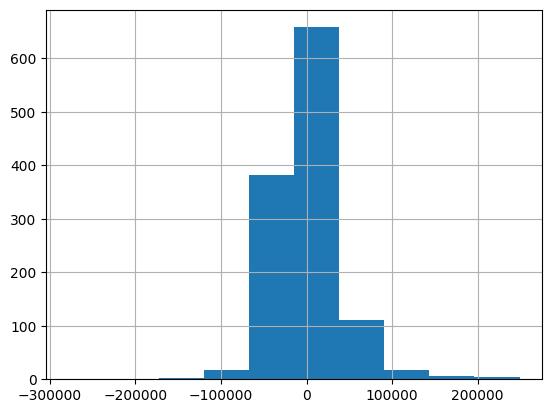

In [41]:
#Histogram of the residuals
(y - model_pipeline.predict(X)).hist()
#The closer the residuals are to 0, the better

In [42]:
#Create the data frame to submit
preds = model_pipeline.predict(X_test)
pdf = pd.DataFrame(preds, columns = ['SalePrice'])
pdf['Id'] = test.index
pdf.to_csv('preds.csv', index = False)

In [43]:
pdf.head()

,SalePrice,Id
0,72993.380137,0
1,197199.058795,1
2,113883.905285,2
3,206255.051592,3
4,130808.010157,4


### Runnning a bunch of trial and error, using this to check

In [44]:
from sklearn.metrics import mean_squared_error
import numpy as np

In [45]:
#Importing
actual = pd.read_csv('solns.csv')

In [46]:
#Getting a MSE to test if we should include/drop certain variables
#Smaller MSE is better
#For some reason this isn't the same value as the one on kaggle, but it's kind of close
np.sqrt(mean_squared_error(actual['SalePrice'], pdf['SalePrice']))

np.float64(37263.237651858275)

Test MSE values and the changes that we made

43985 -- inital (forgot what inital values were included and which weren't)

43909 -- dropped basement and garage condition

41541 -- drop lot frontage

40999 -- fence dropped

40575 -- garage finish added

39864 -- basement exposure added

39142 -- add back masonry area

38754 -- add back basement finish 1

38733 -- add back basement finish 2

38720 -- garage quality removed

38593 -- basement quality removed

37683 -- add bldgtype

37263 -- Full bath added
